# Stable ProbIoU: a score that preserves the geometric signal

**Question:** does the usual ProbIoU formula still measure the right overlap, and give a usable gradient, when boxes use normalized coordinates?

We will change one box center, inspect the arithmetic, then check thin boxes. Inputs are `(cx, cy, w, h, cos(theta), sin(theta))`. Both paths compare **Gaussian representations** of rectangles, not polygon IoU. The baseline reproduces [Ultralytics' equations](https://docs.ultralytics.com/reference/utils/metrics/#ultralytics.utils.metrics.probiou) with `eps=1e-7`, `floor=0`, and `CIoU=False`.

The complete [implementation](stable_probiou.py) and [forward/backward tests](test_stable_probiou.py) are separate files. The core numerical mechanism is visible below; validation and broad test infrastructure are kept out of the lesson.

In [1]:
import math
import xml.etree.ElementTree as ET

import altair as alt
import torch
import vl_convert as vlc
from IPython.display import Image, display
from stable_probiou import stable_probiou, ultralytics_probiou
from test_stable_probiou import notebook_stress_probes


def show_chart(chart):
    """Embed a double-resolution JPEG at its intended display width."""
    svg = vlc.vegalite_to_svg(chart.to_dict())
    width = int(float(ET.fromstring(svg).attrib["width"]))
    display(Image(data=vlc.svg_to_jpeg(svg, scale=2, quality=90), format="jpeg", width=width))


target = torch.tensor([0.5, 0.5, 0.2, 0.1, 1.0, 0.0], dtype=torch.float64)
prediction = target.clone()
prediction[0] += 0.01
prediction.requires_grad_()

/Users/vadstup/Projects/personal/ml-sandbox/.venv/lib/python3.12/site-packages/torch/_subclasses/functional_tensor.py:368: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:84.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


tensor([0.5100, 0.5000, 0.2000, 0.1000, 1.0000, 0.0000], dtype=torch.float64,
       requires_grad=True)

## 1. Move the center by 5% of the box width

The target is `0.2 × 0.1`; prediction moves from center x=0.50 to x=0.51. Equal covariances give a simple independent reference:

`BD = 1.5 × (0.01 / 0.2)² = 0.00375`

`ProbIoU = 1 − sqrt(−expm1(−BD)) = 0.938820122`

The expected loss gradient is `d(1−score)/d(predicted cx) = 6.106524`. A positive loss gradient tells gradient descent to move the prediction left, toward the target.

In [2]:
distance_reference = 1.5 * ((prediction[0] - target[0]) / target[2]).square()
score_reference = 1 - (-torch.expm1(-distance_reference)).sqrt()
gradient_reference = torch.autograd.grad(1 - score_reference, prediction)[0][0]

for name, score_fn in [("Ultralytics", ultralytics_probiou), ("stable", stable_probiou)]:
    score = score_fn(target, prediction)
    gradient = torch.autograd.grad(1 - score, prediction)[0][0]
    print(f"{name:11s} score={score.item():.9f}  loss gradient={gradient.item():.6f}")
print(
    f"reference   score={score_reference.item():.9f}  loss gradient={gradient_reference.item():.6f}"
)

Ultralytics score=0.999552786  loss gradient=0.000000
stable      score=0.938820122  loss gradient=6.106524
reference   score=0.938820122  loss gradient=6.106524


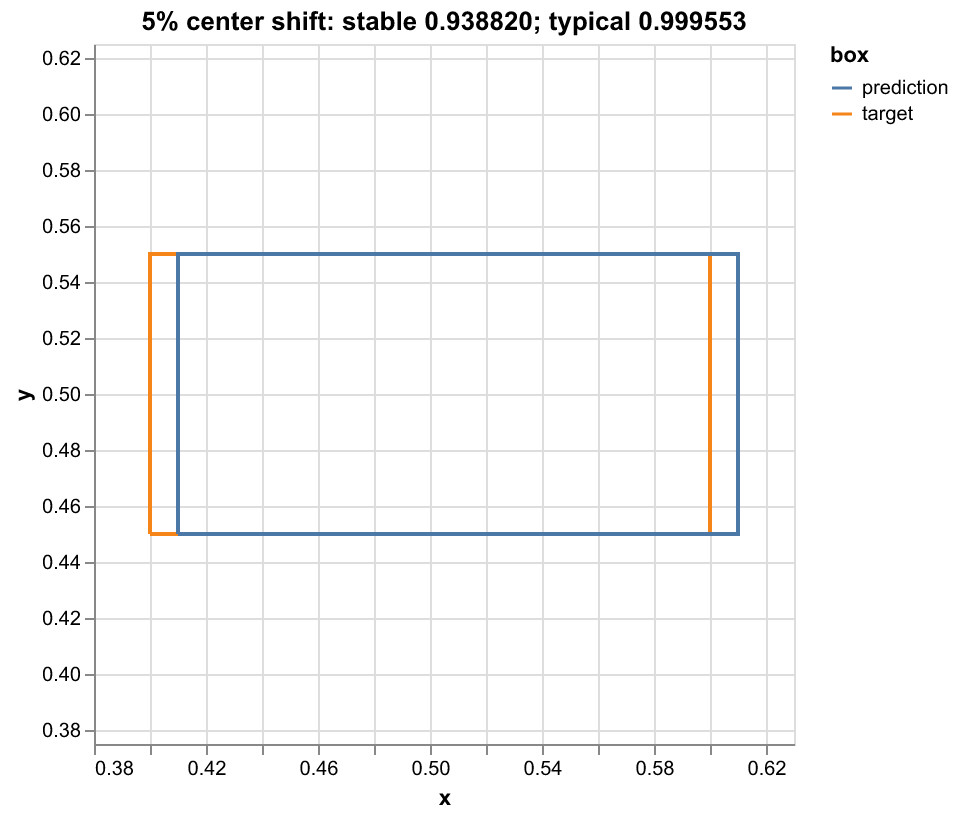

In [3]:
outlines = []
for name, rectangle in [("target", target), ("prediction", prediction.detach())]:
    cx, cy, w, h = rectangle[:4].tolist()
    for order, (u, v) in enumerate([(-1, -1), (1, -1), (1, 1), (-1, 1), (-1, -1)]):
        outlines.append({"x": cx + u * w / 2, "y": cy + v * h / 2, "order": order, "box": name})
chart = (
    alt.Chart(alt.Data(values=outlines))
    .mark_line(strokeWidth=2)
    .encode(
        x=alt.X("x:Q", scale=alt.Scale(domain=[0.38, 0.63])),
        y=alt.Y("y:Q", scale=alt.Scale(domain=[0.375, 0.625])),
        color="box:N",
        order="order:Q",
    )
    .properties(width=350, height=350, title="5% center shift: stable 0.938820; typical 0.999553")
)
show_chart(chart)

## 2. Why the usual formula hides that displacement

For a horizontal rectangle, its Gaussian variances are `w²/12` and `h²/12`. Inspect just the baseline's two distance terms:


In [4]:
eps = 1e-7
variance_x, variance_y = target[2:4].square() / 12
shift = prediction[0] - target[0]
determinant = 4 * variance_x * variance_y
translation = 2 * variance_y * shift.square() / (4 * (determinant + eps))
shape = 0.5 * torch.log(determinant / (determinant + eps) + eps)
raw_distance = translation + shape
clamped_distance = raw_distance.clamp(eps, 100)

print(f"translation: {translation.item(): .9f}  (true value: 0.003750000)")
print(f"shape:       {shape.item(): .9f}  (true value: 0)")
print(f"raw sum:     {raw_distance.item(): .9f}")
print(f"after clamp: {clamped_distance.item(): .9f}")

translation:  0.003716551  (true value: 0.003750000)
shape:       -0.004479820  (true value: 0)
raw sum:     -0.000763269
after clamp:  0.000000100


The shape term should be **zero** because the boxes have the same shape. Epsilon makes it **−0.004479820**, overwhelming translation **0.003716551**. The sum is negative, and the lower clamp replaces it with `1e-7`. That is why the score looks almost perfect and the gradient becomes zero.

This is a regularization bias, not a float32 rounding problem: we reproduced it in float64.

Now shrink or enlarge both boxes and their displacement together. Relative geometry is unchanged, so the score must stay at 0.938820122. A fixed spatial epsilon changes the baseline's result.

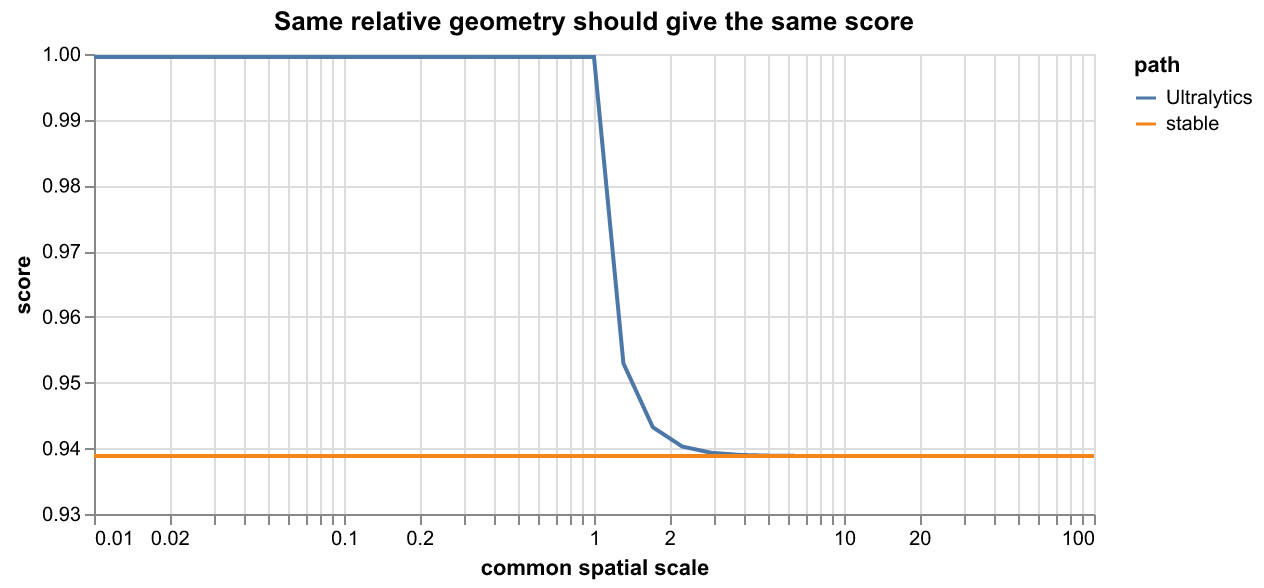

In [5]:
scales = torch.logspace(-2, 2, 35, dtype=torch.float64)
records = []
for scale in scales:
    first, second = target.clone(), prediction.detach().clone()
    first[:4] *= scale
    second[:4] *= scale
    for name, score_fn in [("Ultralytics", ultralytics_probiou), ("stable", stable_probiou)]:
        records.append(
            {"scale": scale.item(), "score": score_fn(first, second).item(), "path": name}
        )
chart = (
    alt.Chart(alt.Data(values=records))
    .mark_line(strokeWidth=2)
    .encode(
        x=alt.X("scale:Q", scale=alt.Scale(type="log"), title="common spatial scale"),
        y=alt.Y("score:Q", scale=alt.Scale(domain=[0.93, 1])),
        color="path:N",
    )
    .properties(width=500, height=230, title="Same relative geometry should give the same score")
)
show_chart(chart)

## 3. How stable arithmetic retains the signal

Start with the easy case: equal horizontal boxes. Avoid epsilon inside the geometric distance and evaluate `exp(x)−1` with `expm1`. Keep the square root as a norm, so equality has PyTorch's zero norm subgradient rather than a singular `sqrt(0)` derivative.

In [6]:
center_residual = math.sqrt(1.5) * (prediction[:2] - target[:2]) / target[2:4]
root_distance = torch.linalg.vector_norm(center_residual)
distance = root_distance.square()
safe_distance = torch.where(distance > 0, distance, torch.ones_like(distance))
factor = torch.where(distance > 0, -torch.expm1(-distance) / safe_distance, 1.0).sqrt()
score = 1 - root_distance * factor

gradient = torch.autograd.grad(1 - score, prediction)[0][0]
print(f"stable core: score={score.item():.9f}  loss gradient={gradient.item():.6f}")
torch.testing.assert_close(score, score_reference)
torch.testing.assert_close(gradient, gradient_reference)

stable core: score=0.938820122  loss gradient=6.106524


Add one variable: **relative rotation or different side lengths**. The expanded covariance determinant normally subtracts two almost equal quantities for thin rotated boxes. Instead, use edge-aligned spreads `p,r` and `q,s`, and relative cosine/sine `C,S`:

```python
P = p * r * q * s
E = (p*r-q*s)**2 + C**2*(p*s-r*q)**2 + S**2*(p*q-r*s)**2
determinant_average = P + E / 4
shape_distance = 0.5 * log1p(E / (4*P))
```

Every determinant contribution is nonnegative. The full implementation builds translation and shape residuals, then uses their norm in the same final transformation shown above. `log1p` preserves small shape differences; `expm1` preserves small distance differences. Float64 intermediates and common scale normalization add numerical headroom.

Exact equality returns score **1** with a chosen **zero subgradient**. Nearby differences retain gradients. This does not make the similarity differentiable at its equality cusp.

## Implementation diff: Ultralytics ProbIoU → stable ProbIoU

For the `0.2 × 0.1` boxes above, moving the center by `0.01` gives **Ultralytics ≈ 0.999553 with zero loss gradient**, versus **stable ≈ 0.938820 with loss gradient ≈ 6.106524**. The latter matches the analytic reference. These changes explain the difference.

This comparison uses the local reproduction of [Ultralytics' ProbIoU equations](https://docs.ultralytics.com/reference/utils/metrics/#ultralytics.utils.metrics.probiou), with `eps=1e-7`, `floor=0`, and `CIoU=False`. Both implementations measure Gaussian box similarity; stable changes how that distance is evaluated.

### Notation used in the diff

Each rectangle is represented by a Gaussian with the same center and covariance as points distributed uniformly inside it. For a uniform interval of length `w`, the variance is `w²/12`: averaging `x²` from `−w/2` to `w/2` gives `(1/w) ∫ x² dx = w²/12`. For example, a side of length `2` has variance `1/3` and standard deviation `2/√12 ≈ 0.577`. This explains the factor **12**.

Before the stable calculation, divide both boxes' side lengths and their center difference by the same scale: the largest side across the pair. The symbols below use those normalized lengths.

| Symbol | Definition | Meaning |
| --- | --- | --- |
| `p`, `r` | `w₁/√12`, `h₁/√12` | First Gaussian's standard deviations along its own width and height axes. |
| `q`, `s` | `w₂/√12`, `h₂/√12` | Second Gaussian's standard deviations along its own width and height axes. |
| `C`, `S` | `cos(θ₂−θ₁)`, `sin(θ₂−θ₁)` | Relative orientation of the two boxes. |
| `Σ₁`, `Σ₂` | Rotated covariance matrices | Each matrix has its box's squared standard deviations along the box's own axes. |
| `P` | `p*r*q*s = sqrt(det(Σ₁)*det(Σ₂))` | Geometric mean of the covariance determinants; called `root_product` in code. |
| `shape_squared` | `((p*r-q*s)² + C²*(p*s-r*q)² + S²*(p*q-r*s)²) / (4*P)` | Nonnegative, dimensionless mismatch in Gaussian shape and orientation; independent of center displacement. |

For identical shapes and orientations, all three residuals in `shape_squared` are zero. For two squares whose side lengths differ by a factor of two, take `p=r=1` and `q=s=2`: then `P=4` and `shape_squared=9/16`. The shape contribution to the Bhattacharyya distance is `0.5 * log1p(shape_squared)`. Thus `shape_squared` measures shape mismatch before the logarithmic distance transformation.

### What changes and why

| Step | Ultralytics baseline | Stable implementation | Why it changed |
| --- | --- | --- | --- |
| Orientation | Convert the supplied direction to an angle with `atan2`, then evaluate sine/cosine. | Normalize the direction vector directly; compute relative rotation with dot/cross products. | Obtain the relative orientation `C,S` defined above without converting vectors to angles and back. This adapter difference alone does not fix the epsilon bias. |
| Spatial scale and precision | Evaluate squared sides and covariance products in the input dtype. | Convert to float64 and divide sides and center differences by the pair's largest side. Cast the score back to the input dtype. | Reduce overflow/underflow and remove common spatial scale from the geometry before forming products. |
| Covariance determinant | Subtract covariance products: `(a+d)*(b+e) - (c+f)**2`. | Use `P * (1 + shape_squared)`, with `P` and the nonnegative shape residuals defined above. | Avoid subtracting nearly equal large terms for thin rotated boxes. The average covariance determinant is one quarter of the baseline's summed covariance determinant. |
| Shape distance | Add epsilon to the determinant ratio before taking `log`. | Use `0.5 * log1p(shape_squared)`. | Identical shapes give exactly zero; small shape differences retain precision. |
| Translation distance | Divide the covariance expansion by a determinant plus epsilon. | Form edge-aligned translation residuals whose squared norm gives the translation distance. | Preserve relative displacement without a fixed epsilon changing the geometry. |
| Near-zero distance | Clamp total distance to at least epsilon; use `sqrt(1 - exp(-BD) + eps)`. | Use a residual norm and an `expm1` correction, with finite fallback denominators at zero. | Avoid an epsilon-induced flat region and cancellation in `1 - exp(-BD)`. Equality gets a chosen zero norm subgradient. |
| Far-separated boxes | Cap total distance at 100. | Clamp each normalized translation residual to `[-32, 32]`; clamp the final score to `[0, 1]`. | Stop extreme translation growth after the similarity is already numerically zero. This changes saturated arithmetic, not nearby overlap behavior. |

### The central formula change

Let `z` be the combined translation/shape residual and `BD = ||z||²`. Omitting the baseline's upper cap for readability, the final-score change is:

```diff
- BD = raw_distance.clamp_min(eps)
- score = 1 - sqrt(1 - exp(-BD) + eps)
+ root_distance = norm(z)
+ BD = root_distance**2
+ factor = sqrt(-expm1(-BD) / BD)  # limit is 1 at BD = 0
+ score = 1 - root_distance * factor
```

For positive distance, the stable expression is algebraically `1 − sqrt(1 − exp(−BD))`. The norm supplies the zero subgradient at equality; `expm1` accurately computes the small exponential difference. The actual implementation uses safe denominators so even inactive `torch.where` branches remain finite during backward.

**Tradeoff:** stable uses float64 work and synchronizing validation, requires CPU/CUDA, and rejects geometry outside its documented dynamic range. It cannot recover information already rounded away in the input or represent gradients beyond the input dtype's range. This is a numerical reformulation with explicit boundary behavior, not evidence of improved detector accuracy.


## 4. A finite score can produce NaNs in backward

Use **identical** float32 boxes. Try a thin box (`w=1, h=1e-12`) and a tiny normalized square (`w=h=1e-6`). Both should have score 1 and zero gradients. The next cell calls **`loss.backward()`**, just as a training loop does, and prints `prediction.grad` in the order `(cx, cy, w, h, cos, sin)`.

The typical formula returns a finite score, but its width, height, and direction gradients become **NaN**. The stable implementation returns score 1 and six zero gradients. Assertions check the forward and backward states separately, so these failures cannot pass unnoticed.

Why? The baseline's determinant product underflows to zero in float32. Its square root has a singular derivative there: backward can encounter `0 × infinity = NaN`. The final distance clamp does not make the earlier backward intermediates safe. The stable path uses normalized float64 geometry and a residual norm with a defined zero subgradient at equality.

In [7]:
for case, width, height in [("thin box", 1.0, 1e-12), ("tiny normalized square", 1e-6, 1e-6)]:
    target_box = torch.tensor([0.5, 0.5, width, height, 1.0, 0.0], dtype=torch.float32)
    print(f"\n{case}: identical float32 boxes; gradient order = cx, cy, w, h, cos, sin")
    for name, score_fn in [("Ultralytics", ultralytics_probiou), ("stable", stable_probiou)]:
        predicted = target_box.clone().requires_grad_()
        score = score_fn(target_box, predicted)
        loss = 1 - score
        loss.backward()
        gradient = predicted.grad
        assert gradient is not None
        print(f"{name:11s} score={score.item():.9f}; loss={loss.item():.9f}")
        print(
            f"            gradient={gradient.tolist()}; has NaN={bool(torch.isnan(gradient).any())}"
        )
        assert bool(torch.isfinite(score)), "This example must isolate a backward-only failure"
        if name == "Ultralytics":
            assert bool(torch.isnan(gradient[2:]).all())
        else:
            assert score.item() == 1.0
            assert bool(torch.isfinite(gradient).all())
            assert bool((gradient == 0).all())


thin box: identical float32 boxes; gradient order = cx, cy, w, h, cos, sin
Ultralytics score=0.999531806; loss=0.000468194
            gradient=[0.0, 0.0, nan, nan, nan, nan]; has NaN=True
stable      score=1.000000000; loss=0.000000000
            gradient=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]; has NaN=False

tiny normalized square: identical float32 boxes; gradient order = cx, cy, w, h, cos, sin
Ultralytics score=0.999531806; loss=0.000468194
            gradient=[0.0, 0.0, nan, nan, nan, nan]; has NaN=True
stable      score=1.000000000; loss=0.000000000
            gradient=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]; has NaN=False


Broaden this identity test across box sizes and aspect ratios. The plot checks **both arguments' gradients** independently of the score. Green means both are finite; orange means backward alone fails; red means forward fails. This grid uses 98 identity probes per path; it establishes finiteness, not accuracy by itself. The analytic example above and independent matrix-reference tests supply accuracy evidence.

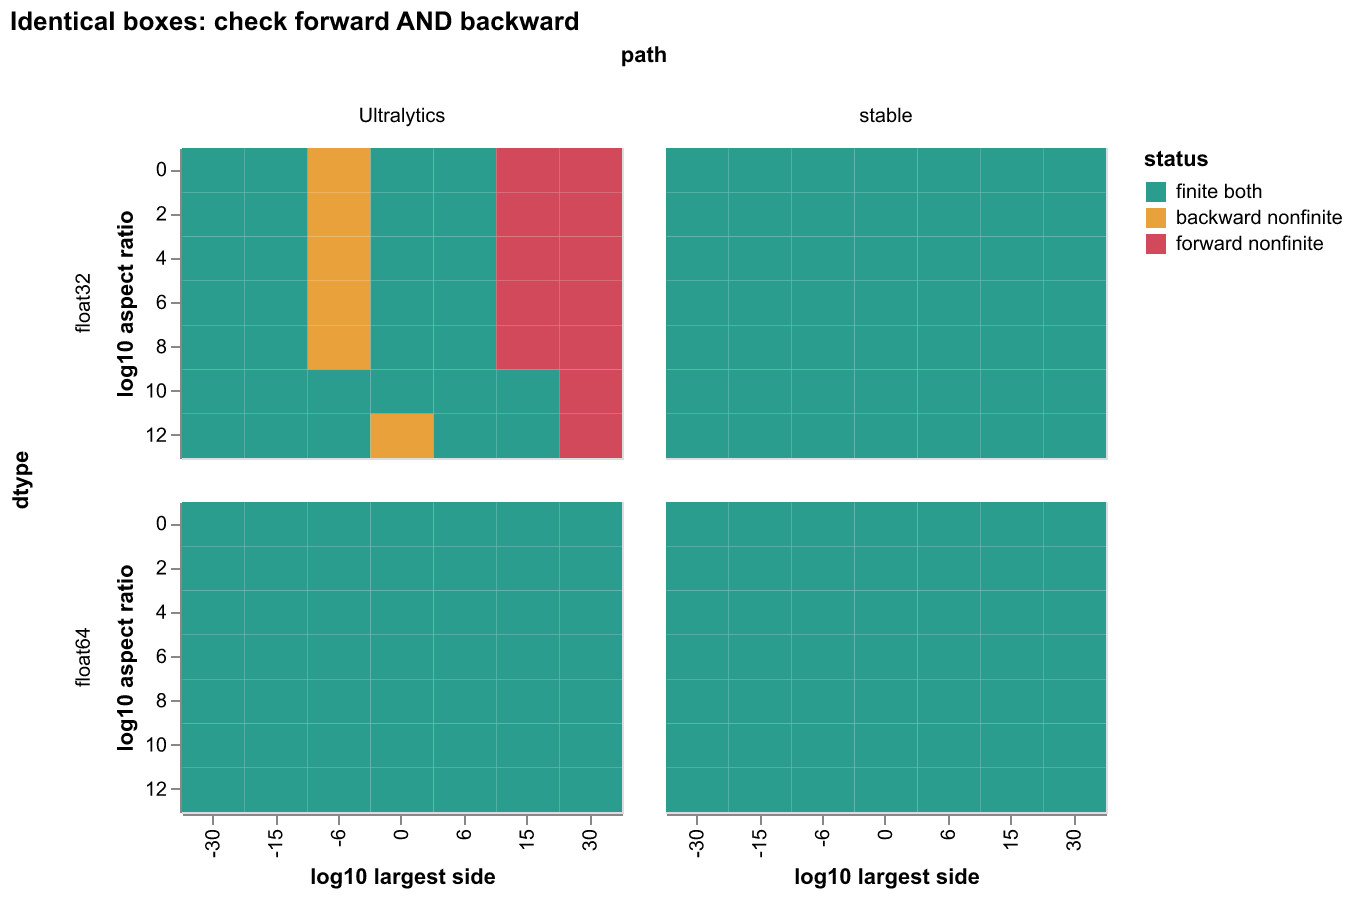

stable {'finite both': 98, 'backward nonfinite': 0, 'forward nonfinite': 0}
Ultralytics {'finite both': 80, 'backward nonfinite': 6, 'forward nonfinite': 12}


In [8]:
probes = notebook_stress_probes()
chart = (
    alt.Chart(alt.Data(values=probes))
    .mark_rect()
    .encode(
        x=alt.X("scale:O", title="log10 largest side"),
        y=alt.Y("aspect:O", title="log10 aspect ratio"),
        color=alt.Color(
            "status:N",
            scale=alt.Scale(
                domain=["finite both", "backward nonfinite", "forward nonfinite"],
                range=["#2a9d8f", "#e9a23b", "#d1495b"],
            ),
        ),
        column="path:N",
        row="dtype:N",
    )
    .properties(width=220, height=155, title="Identical boxes: check forward AND backward")
)
show_chart(chart)
for path in ("stable", "Ultralytics"):
    selected = [p for p in probes if p["path"] == path]
    print(
        path,
        {
            status: sum(p["status"] == status for p in selected)
            for status in ("finite both", "backward nonfinite", "forward nonfinite")
        },
    )
assert all(p["status"] == "finite both" for p in probes if p["path"] == "stable")

## What is better—and what it costs

Here, stable ProbIoU preserves the analytic similarity and gradient, stays invariant to common spatial rescaling, and avoids the demonstrated thin-box backward failure. Its numerical advantage combines different algebra with higher internal precision.

The cost is float64 computation and synchronizing validation. CPU/CUDA are supported by the implementation, but these experiments ran on CPU; MPS cannot execute its float64 path. Pairwise side ratios below `1e-30` or offsets above `1e30` times the largest side are rejected. Gradients beyond the input dtype's range still cannot be represented. These results do not establish faster training or better detection accuracy.

Run `uv run pytest 04_stable_probiou -q` for independent reference checks, finite differences, all twelve input gradients, broadcasting, dtype coverage, equivalences, and extreme geometry.

ProbIoU measures similarity between Gaussian box representations. The stable path preserves that measurement and its useful gradient in the examples where the usual arithmetic loses them.